Assignment 1

f(x,y)=(x-3)^+2+(y+2)^2


Start: x = 0.0000, y = 0.0000, total f(x, y) = 13.0000
Iterations 1: x = 0.6000, y = -0.4000, total f(x, y) = 8.3200
Iterations 2: x = 1.0800, y = -0.7200, total f(x, y) = 5.3248
Iterations 3: x = 1.4640, y = -0.9760, total f(x, y) = 3.4079
Iterations 4: x = 1.7712, y = -1.1808, total f(x, y) = 2.1810
Iterations 5: x = 2.0170, y = -1.3446, total f(x, y) = 1.3959
Iterations 6: x = 2.2136, y = -1.4757, total f(x, y) = 0.8934
Iterations 7: x = 2.3709, y = -1.5806, total f(x, y) = 0.5717
Iterations 8: x = 2.4967, y = -1.6645, total f(x, y) = 0.3659
Iterations 9: x = 2.5973, y = -1.7316, total f(x, y) = 0.2342
Iterations 10: x = 2.6779, y = -1.7853, total f(x, y) = 0.1499
Iterations 11: x = 2.7423, y = -1.8282, total f(x, y) = 0.0959
Iterations 12: x = 2.7938, y = -1.8626, total f(x, y) = 0.0614
Iterations 13: x = 2.8351, y = -1.8900, total f(x, y) = 0.0393
Iterations 14: x = 2.8681, y = -1.9120, total f(x, y) = 0.0251
Iterations 15: x = 2.8944, y = -1.9296, total f(x, y) = 0.0161
Iteration

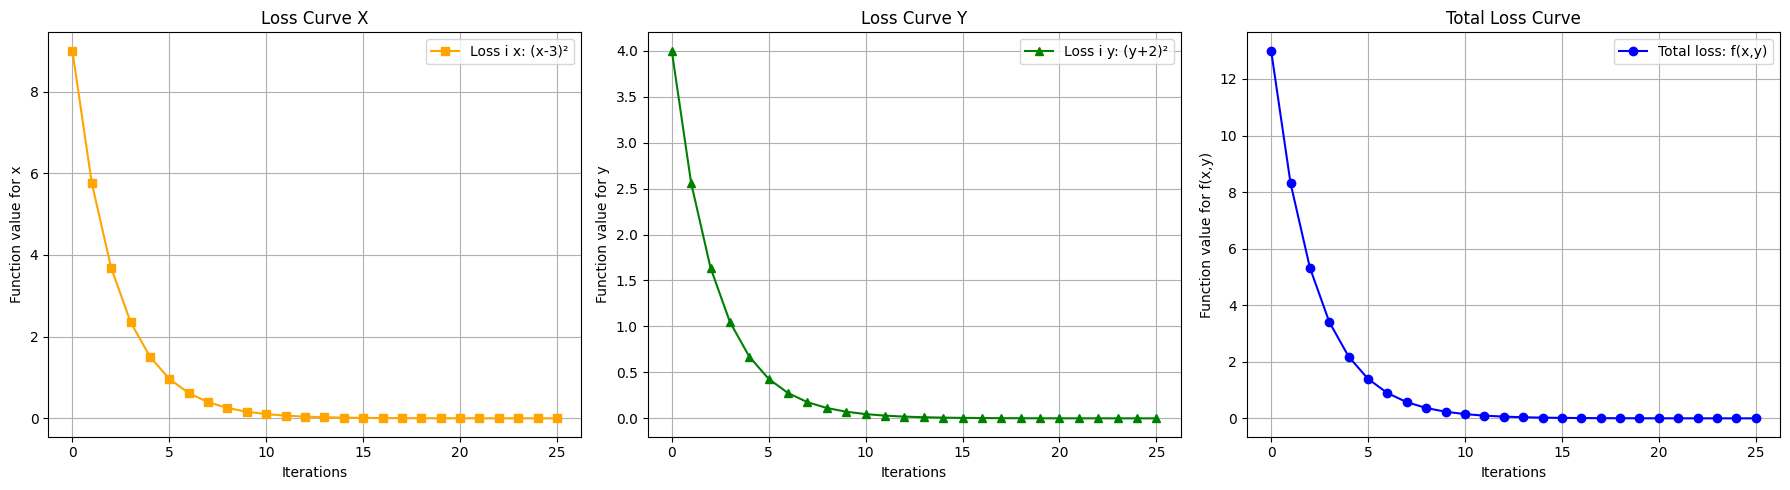

In [9]:
import numpy as np
import matplotlib.pyplot as plt

def f(x, y):
    return (x - 3)**2 + (y + 2)**2

def f_x(x):
    return (x - 3)**2
def f_y(y):
    return (y + 2)**2

def gradient(x, y):
    df_dx = 2 * (x - 3)
    df_dy = 2 * (y + 2)
    return df_dx, df_dy

def gradient_descent(starting_point, learning_rate, iterations):
    x, y = starting_point

    loss_history = [f(x, y)]
    loss_x = [f_x(x)]
    loss_y = [f_y(y)]
    
    print(f"Start: x = {x:.4f}, y = {y:.4f}, total f(x, y) = {loss_history[0]:.4f}")
    
    for i in range(iterations):
        df_dx, df_dy = gradient(x, y)

        x -= learning_rate * df_dx
        y -= learning_rate * df_dy

        loss_history.append(f(x, y))
        loss_x.append(f_x(x))
        loss_y.append(f_y(y))
        
        print(f"Iterations {i+1}: x = {x:.4f}, y = {y:.4f}, total f(x, y) = {loss_history[-1]:.4f}")
    return x, y, loss_history, loss_x, loss_y

starting_point = (0, 0)
learning_rate = 0.1
iterations = 25  
min_x, min_y, loss_history, loss_x, loss_y = gradient_descent(starting_point, learning_rate, iterations)

print(f"\nMinimum: x = {min_x:.4f}, y = {min_y:.4f}")
print(f"Theoretical minimum: x = 3.0000, y = -2.0000")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

ax1.plot(range(iterations + 1), loss_x, marker='s', color='orange', label='Loss i x: (x-3)²')
ax1.set_xlabel('Iterations')
ax1.set_ylabel('Function value for x')
ax1.set_title('Loss Curve X')
ax1.legend()
ax1.grid(True)

ax2.plot(range(iterations + 1), loss_y, marker='^', color='green', label='Loss i y: (y+2)²')
ax2.set_xlabel('Iterations')
ax2.set_ylabel('Function value for y')
ax2.set_title('Loss Curve Y')
ax2.legend()
ax2.grid(True)

ax3.plot(range(iterations + 1), loss_history, marker='o', color='blue', label='Total loss: f(x,y)')
ax3.set_xlabel('Iterations')
ax3.set_ylabel('Function value for f(x,y)')
ax3.set_title('Total Loss Curve')
ax3.legend()
ax3.grid(True)

plt.tight_layout()
plt.show()

Question 2: Deep Learning for Image Classification



In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, f1_score


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_transforms = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)) 
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762))
])

trainset = torchvision.datasets.CIFAR100(root='./data', train=True, download=True, transform=train_transforms)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=test_transforms)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False, num_workers=2)


class CNN(nn.Module):
    def __init__(self, num_classes=100):
        super(CNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), 
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), 
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), 
            
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 2 * 2, 1024),
            nn.ReLU(),
            nn.Dropout(0.5), 
            nn.Linear(1024, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = CNN().to(device)

weights_before = model.features[0].weight.data.cpu().clone()

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 15
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    history['train_loss'].append(running_loss / len(trainloader))
    history['train_acc'].append(100. * correct / total)
    
    model.eval()
    val_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
    history['val_loss'].append(val_loss / len(testloader))
    history['val_acc'].append(100. * correct / total)
    
    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {history['train_loss'][-1]:.4f}, Train Acc: {history['train_acc'][-1]:.2f}% - Val Loss: {history['val_loss'][-1]:.4f}, Val Acc: {history['val_acc'][-1]:.2f}%")

weights_after = model.features[0].weight.data.cpu().clone()

model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

f1 = f1_score(all_targets, all_preds, average='macro')
accuracy = history['val_acc'][-1]

cm = confusion_matrix(all_targets, all_preds)
FP = cm.sum(axis=0) - np.diag(cm) 
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

print("\n--- Evaluation Metrics ---")
print(f"Accuracy: {accuracy:.2f}%")
print(f"F1-score (Macro): {f1:.4f}")
print(f"Total True Positives (TP): {TP.sum()}")
print(f"Total True Negatives (TN): {TN.sum()}")
print(f"Total False Positives (FP): {FP.sum()}")
print(f"Total False Negatives (FN): {FN.sum()}")

100.0%


Extracting ./data/cifar-100-python.tar.gz to ./data
Files already downloaded and verified
Epoch 1/15 - Train Loss: 3.9829, Train Acc: 7.90% - Val Loss: 3.5935, Val Acc: 14.23%
Epoch 2/15 - Train Loss: 3.4053, Train Acc: 16.55% - Val Loss: 3.0469, Val Acc: 22.22%
Epoch 3/15 - Train Loss: 3.0975, Train Acc: 21.77% - Val Loss: 2.8000, Val Acc: 27.64%
Epoch 4/15 - Train Loss: 2.8671, Train Acc: 26.23% - Val Loss: 2.5688, Val Acc: 33.28%
Epoch 5/15 - Train Loss: 2.6990, Train Acc: 29.90% - Val Loss: 2.3853, Val Acc: 36.51%
Epoch 6/15 - Train Loss: 2.5559, Train Acc: 32.57% - Val Loss: 2.2262, Val Acc: 40.00%
Epoch 7/15 - Train Loss: 2.4323, Train Acc: 35.38% - Val Loss: 2.1613, Val Acc: 42.13%
Epoch 8/15 - Train Loss: 2.3280, Train Acc: 37.75% - Val Loss: 2.0598, Val Acc: 44.00%
Epoch 9/15 - Train Loss: 2.2313, Train Acc: 40.12% - Val Loss: 2.0675, Val Acc: 44.04%
Epoch 10/15 - Train Loss: 2.1374, Train Acc: 42.06% - Val Loss: 1.9161, Val Acc: 47.44%
Epoch 11/15 - Train Loss: 2.0574, Train 

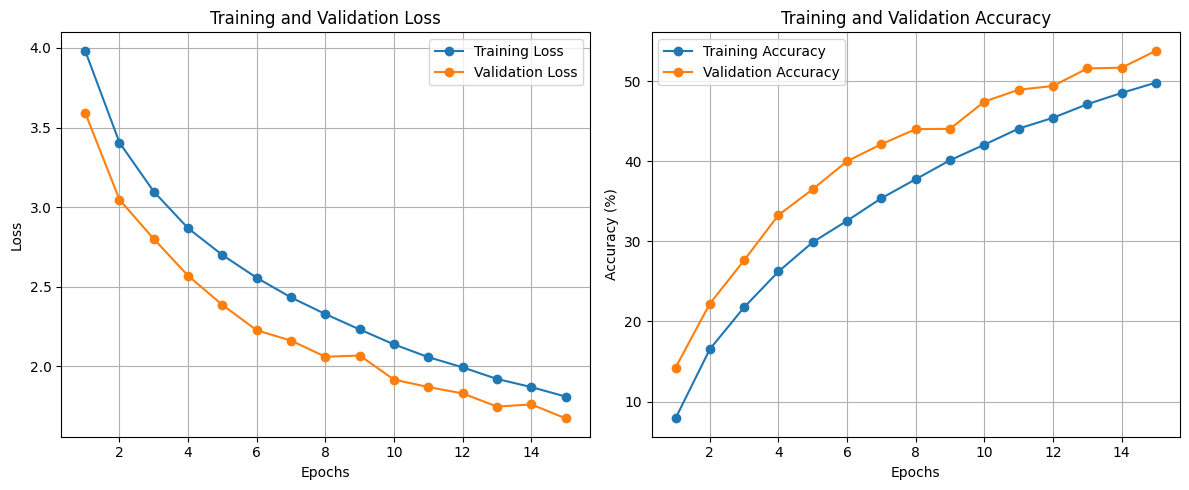

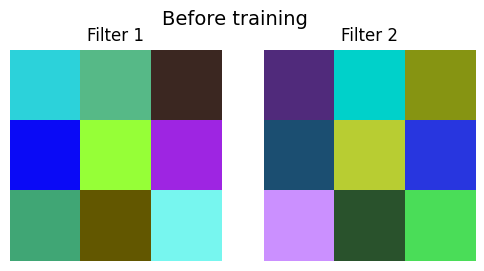

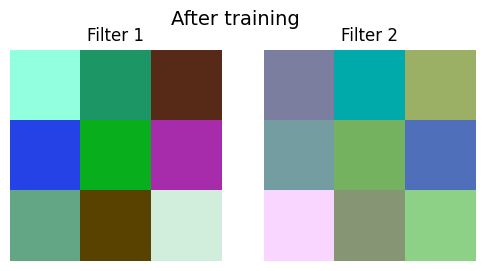

In [4]:
def plot_filters(weights, title):
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    fig.suptitle(title, fontsize=14)
    
    for i in range(2):
        filt = weights[i].numpy() 
        
        f_min, f_max = filt.min(), filt.max()
        filt_norm = (filt - f_min) / (f_max - f_min)
        filt_norm = filt_norm.transpose(1, 2, 0)

        axes[i].imshow(filt_norm)
        axes[i].set_title(f"Filter {i+1}")
        axes[i].axis('off') 
        
    plt.show()


epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

plot_filters(weights_before, "Before training")
plot_filters(weights_after, "After training")

In [5]:
from torchvision.models import resnet50, ResNet50_Weights

resnet_model = resnet50(weights=ResNet50_Weights.DEFAULT)
num_ftrs = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_ftrs, 100)
resnet_model = resnet_model.to(device)

optimizer_resnet = optim.Adam(resnet_model.parameters(), lr=0.0001)
weights_before = model.features[0].weight.data.cpu().clone()

criterion = nn.CrossEntropyLoss()
resNet_optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 50
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}




for epoch in range(epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        resNet_optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        resNet_optimizer.step()
        
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    history['train_loss'].append(running_loss / len(trainloader))
    history['train_acc'].append(100. * correct / total)
    
    model.eval()
    val_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
    history['val_loss'].append(val_loss / len(testloader))
    history['val_acc'].append(100. * correct / total)
    
    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {history['train_loss'][-1]:.4f}, Train Acc: {history['train_acc'][-1]:.2f}% - Val Loss: {history['val_loss'][-1]:.4f}, Val Acc: {history['val_acc'][-1]:.2f}%")

weights_after = model.features[0].weight.data.cpu().clone()

model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

f1 = f1_score(all_targets, all_preds, average='macro')
accuracy = history['val_acc'][-1]

cm = confusion_matrix(all_targets, all_preds)
FP = cm.sum(axis=0) - np.diag(cm) 
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

print("\n--- Evaluation Metrics ---")
print(f"Accuracy: {accuracy:.2f}%")
print(f"F1-score (Macro): {f1:.4f}")
print(f"Total True Positives (TP): {TP.sum()}")
print(f"Total True Negatives (TN): {TN.sum()}")
print(f"Total False Positives (FP): {FP.sum()}")
print(f"Total False Negatives (FN): {FN.sum()}")

Epoch 1/50 - Train Loss: 1.7625, Train Acc: 50.80% - Val Loss: 1.6437, Val Acc: 54.37%
Epoch 2/50 - Train Loss: 1.7047, Train Acc: 52.36% - Val Loss: 1.6277, Val Acc: 55.25%
Epoch 3/50 - Train Loss: 1.6620, Train Acc: 53.45% - Val Loss: 1.6009, Val Acc: 55.60%
Epoch 4/50 - Train Loss: 1.6132, Train Acc: 54.77% - Val Loss: 1.6249, Val Acc: 55.41%
Epoch 5/50 - Train Loss: 1.5802, Train Acc: 55.26% - Val Loss: 1.5681, Val Acc: 56.50%
Epoch 6/50 - Train Loss: 1.5332, Train Acc: 56.60% - Val Loss: 1.5571, Val Acc: 57.26%
Epoch 7/50 - Train Loss: 1.4840, Train Acc: 57.66% - Val Loss: 1.5428, Val Acc: 57.32%
Epoch 8/50 - Train Loss: 1.4661, Train Acc: 58.44% - Val Loss: 1.5494, Val Acc: 57.51%
Epoch 9/50 - Train Loss: 1.4150, Train Acc: 59.42% - Val Loss: 1.4935, Val Acc: 59.41%
Epoch 10/50 - Train Loss: 1.3899, Train Acc: 60.15% - Val Loss: 1.5150, Val Acc: 58.76%
Epoch 11/50 - Train Loss: 1.3656, Train Acc: 60.62% - Val Loss: 1.4915, Val Acc: 59.38%
Epoch 12/50 - Train Loss: 1.3317, Train A

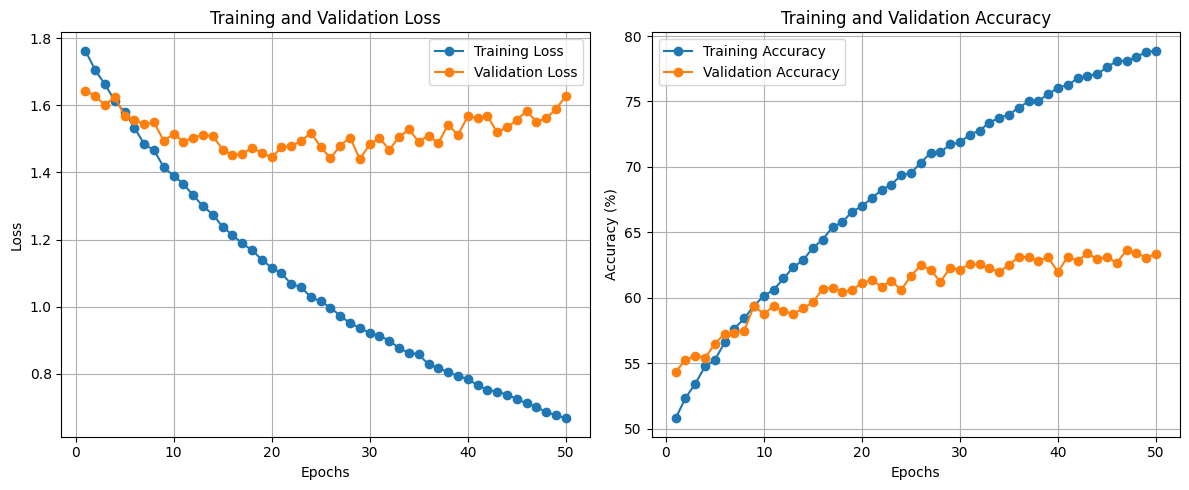

In [6]:
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()